### Setup 

In [1]:
import numpy as np
import keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

### Load Dataset

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print(X.shape)
print(y.shape)

(569, 30)
(569,)


### TRAIN / VALIDATION / TEST SPLIT 

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

### SCALING

In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

X_test = scaler.transform(X_test)

### BUILD MODEL

In [6]:
model = keras.Sequential([
    keras.Input(shape =(30,)),
    layers.Dense(
        64,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),

    layers.ReLU(),

    layers.Dropout(0.3),

    layers.Dense(
        32,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.BatchNormalization(),

    layers.ReLU(),

    layers.Dropout(0.2),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

### Architecture

```text
30 inputs
    ↓
Dense 64
    ↓
He Initialization
    ↓
L2
    ↓
BatchNorm
    ↓
ReLU
    ↓
Dropout 30%
    ↓
Dense 32
    ↓
He Initialization
    ↓
L2
    ↓
BatchNorm
    ↓
ReLU
    ↓
Dropout 20%
    ↓
Dense 1
    ↓
Sigmoid

### Compile

In [7]:
optimizer = keras.optimizers.Adam(
    learning_rate=0.001
)

model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

### Inspect Model

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 192 (768.00 B)

### Callbacks

In [9]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6
)

### Train

In [10]:
history = model.fit(
    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=100,

    batch_size=32,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.6154 - loss: 0.9471 - precision: 0.6447 - recall: 0.8596 - val_accuracy: 0.7582 - val_loss: 0.7147 - val_precision: 0.7215 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7253 - loss: 0.7132 - precision: 0.7302 - recall: 0.8904 - val_accuracy: 0.8901 - val_loss: 0.5113 - val_precision: 0.8507 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8489 - loss: 0.5429 - precision: 0.8446 - recall: 0.9298 - val_accuracy: 0.9560 - val_loss: 0.4292 - val_precision: 0.9492 - val_recall: 0.9825 - learning_rate: 0.0010
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8791 - loss: 0.5054 - precision: 0.8740 - recall: 0.9430 - val_accuracy: 0.9670 - val_loss: 0.3884 - val_precision: 0.9655 - val_recall: 0.9825 - learning_rate: 0.0010
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.91

### Evaluate

In [11]:
results = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

for name, value in zip(
    model.metrics_names,
    results
):
    print(f"{name}: {value:.4f}")

loss: 0.1696
compile_metrics: 0.9561


### Predictions

In [12]:
probabilities = model.predict(
    X_test
).ravel()

predictions = (
    probabilities >= 0.5
).astype(int)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


### Classification Report

In [13]:
print(
    classification_report(
        y_test,
        predictions
    )
)

              precision    recall  f1-score   support

           0       0.93      0.95      0.94        42
           1       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



### Confusion Matrix

In [14]:
cm = confusion_matrix(
    y_test,
    predictions
)

print(cm)

[[40  2]
 [ 3 69]]


### Visualize

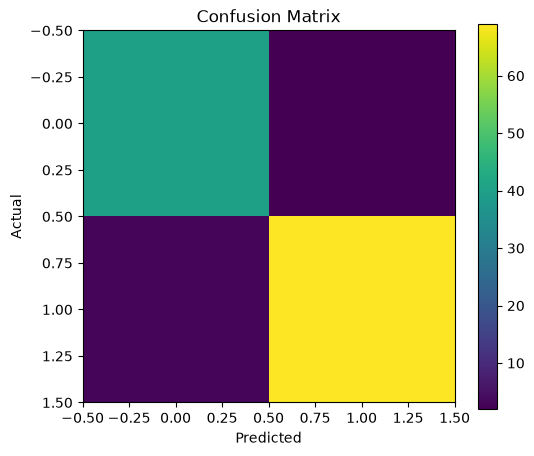

In [15]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

plt.show()

### Training Curves

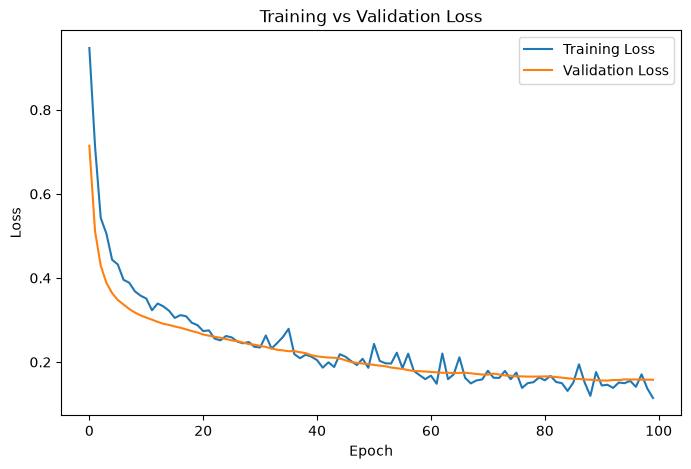

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()

plt.show()

### Accuracy

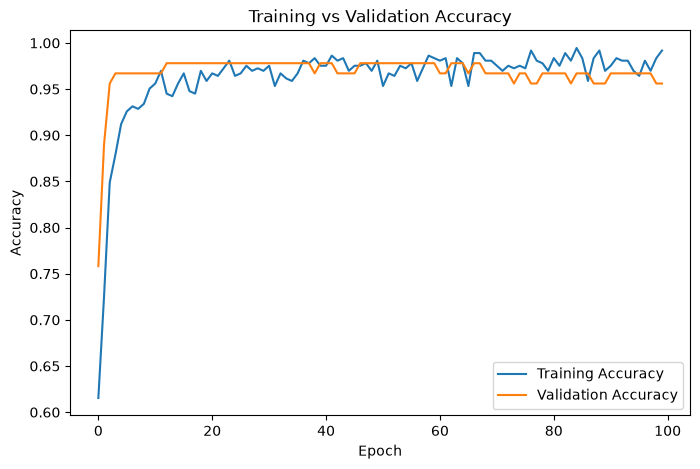

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()

plt.show()